# TS7: Filtrado digital lineal de ECG
## Alumno: Matías Carbajal
## Materia: Análisis y Procesamiento de Señales (APS)
## Carrera: Ingeniería Telecomunicaciones
## Fecha: 4 de noviembre de 2026

# 1. Introducción Teórica:

(filtros fir e iir).

# 2. Análisis y Desarrollo.

## 2.1 Filtros IIR.

In [19]:
#IMPORTACIONES 
import numpy as np
import scipy.io as sio
import scipy.signal as signal              
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

In [20]:
#%% ============================================================
# 1. LECTURA DE LA SEÑAL ECG
# ============================================================

fs_ecg = 1000.0  # Frecuencia de muestreo [Hz]

# Cargar archivo .mat
mat_struct = sio.loadmat('./ECG_TP4.mat')

# Extraer señal ECG
ecg_one_lead = mat_struct['ecg_lead'].flatten().astype(float)

# Patrones de latidos
hb_1 = mat_struct['heartbeat_pattern1']
hb_2 = mat_struct['heartbeat_pattern2']

# Cantidad de muestras y vector temporal
N = len(ecg_one_lead)
t_ecg = np.arange(N) / fs_ecg
# ============================================================


In [21]:
#%%................... Diseño de filtro ...................

wp = 35       # [Hz] Frecuencia límite de banda pasante
ws = 50       # [Hz] Frecuencia límite de banda de rechazo
Gpass = 3     # [dB] Atenuación máxima en banda pasante
Gstop = 40    # [dB] Atenuación mínima en banda de rechazo

ripple = Gpass
att = Gstop

# Diseño de los tres filtros
sos_butt = signal.iirdesign(
    wp, ws, Gpass, Gstop,
    ftype='butter', fs=fs_ecg, output='sos'
)

sos_cheby2 = signal.iirdesign(
    wp, ws, Gpass, Gstop,
    ftype='cheby2', fs=fs_ecg, output='sos'
)

sos_cauer = signal.iirdesign(
    wp, ws, Gpass, Gstop,
    ftype='cauer', fs=fs_ecg, output='sos'
)

y_min, y_max = -100, 5
# ============================================================

In [ ]:
Explicar xq se eligio estos valores para el diseño de filtro

In [27]:
#%% Función para calcular y graficar las respuestas

def calc_resp(sos, leg_str, fig_n_axes):

    # Respuesta en frecuencia
    f, h = sig.freqz_sos(sos, worN=8192, fs=fs_ecg)

    # Módulo en dB
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))

    # Fase
    fase_rad = np.unwrap(np.angle(h))

    # Retardo de grupo
    omega = 2 * np.pi * f
    retardo_s = -np.gradient(fase_rad, omega)

    # Evitar graficar retardos donde el filtro rechaza
    # prácticamente toda la señal
    umbral_db = -80
    valido = modulo_db > umbral_db
    retardo_s_plot = np.where(valido, retardo_s, np.nan)

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    # Módulo
    ax_mod.plot(f, modulo_db, linewidth=1.5, label=leg_str)
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en frecuencia y plantilla")
    ax_mod.grid(True)

    # Fase
    ax_fase.plot(f, fase_rad, label=leg_str, linewidth=1.2)
    ax_fase.axvline(wp, color="gray", linestyle=":")
    ax_fase.axvline(ws, color="gray", linestyle=":")
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)

    # Retardo de grupo
    plt.figure(2, figsize=(10, 4))
    plt.plot(f, retardo_s_plot, label=leg_str)
    plt.axvline(wp, color="orange", linestyle="--",
                label=f"wp = {wp} Hz")
    plt.axvline(ws, color="red", linestyle="--",
                label=f"ws = {ws} Hz")
    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("Retardo de grupo (s)")
    plt.title("Retardo de grupo del filtro IIR")
    plt.grid(True)
    plt.legend()
# ============================================================

C:\Users\DELL\AppData\Local\Temp\ipykernel_9536\2858918784.py:42: UserWarning: Ignoring specified arguments in this call because figure with num: 2 already exists
  plt.figure(2, figsize=(10, 4))


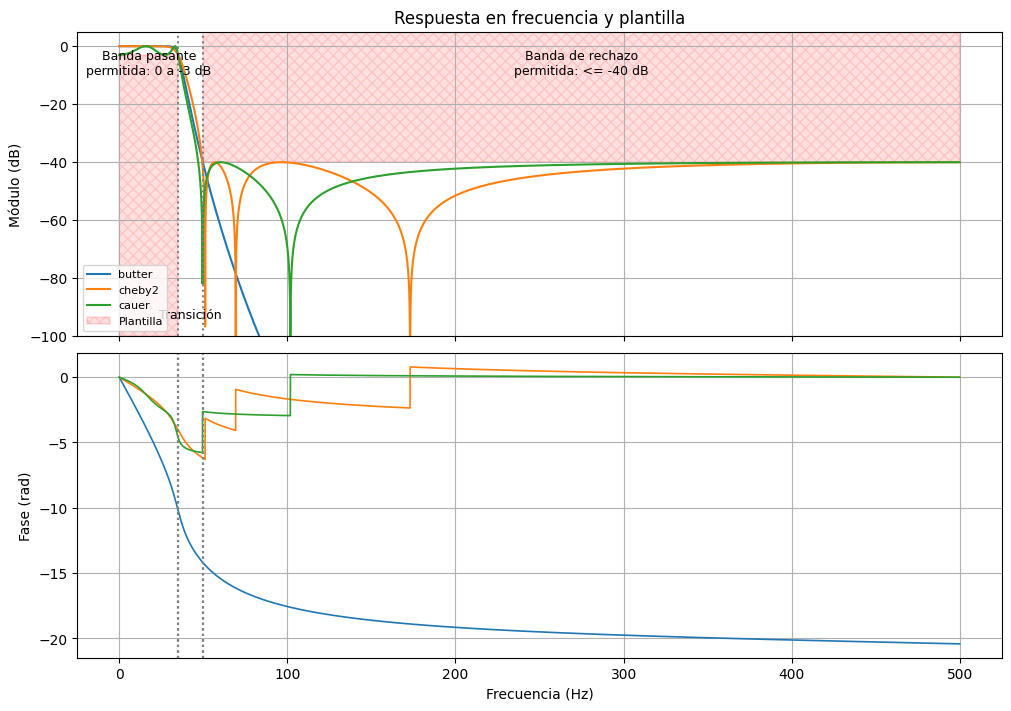

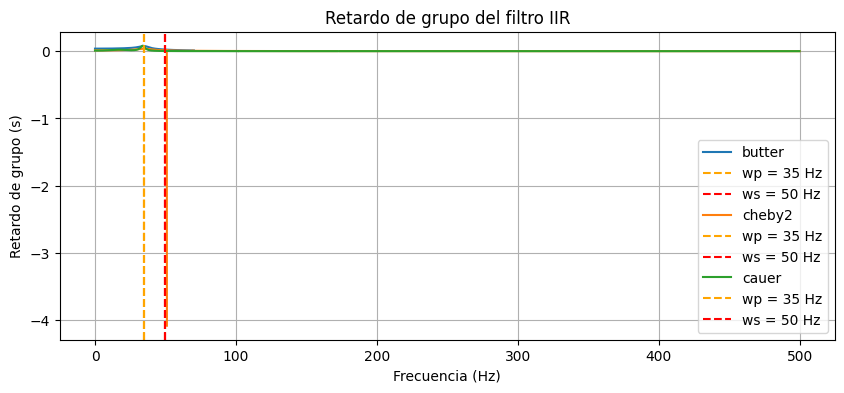

In [28]:
#%% Graficar las respuestas de los filtros

plt.close('all')

fig_n_axes = plt.subplots(
    2, 1, sharex=True, num=1,
    figsize=(10, 7), constrained_layout=True
)

calc_resp(sos_butt, 'butter', fig_n_axes)
calc_resp(sos_cheby2, 'cheby2', fig_n_axes)
calc_resp(sos_cauer, 'cauer', fig_n_axes)


#%% Graficar la plantilla del filtro

(fig, (ax_mod, ax_fase)) = fig_n_axes

# Banda pasante
rect_pasante = Rectangle(
    (0, y_min), wp, -ripple - y_min,
    facecolor="red", alpha=0.12,
    edgecolor="red", hatch="xxx",
    linewidth=1.2, label='Plantilla'
)

ax_mod.add_patch(rect_pasante)

# Banda de rechazo
rect_rechazo = Rectangle(
    (ws, -att), fs_ecg / 2 - ws, y_max + att,
    facecolor="red", alpha=0.12,
    edgecolor="red", hatch="xxx",
    linewidth=1.2
)

ax_mod.add_patch(rect_rechazo)

# Límites de frecuencia
ax_mod.axvline(wp, color="gray", linestyle=":")
ax_mod.axvline(ws, color="gray", linestyle=":")

# Etiquetas
ax_mod.text(
    wp / 2, y_max - 6,
    "Banda pasante\npermitida: 0 a -3 dB",
    ha="center", va="top", fontsize=9
)

ax_mod.text(
    (ws + fs_ecg / 2) / 2, y_max - 6,
    "Banda de rechazo\npermitida: <= -40 dB",
    ha="center", va="top", fontsize=9
)

ax_mod.text(
    (wp + ws) / 2, y_min + 5,
    "Transición",
    ha="center", va="bottom", fontsize=9
)

ax_mod.legend(loc="lower left", fontsize=8)


In [ ]:
(hacer analisis la rta en frecuencia  y del retardo de grupo de cada filtro)

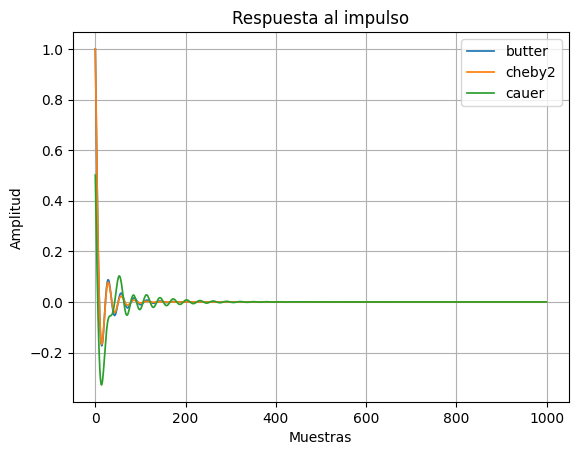

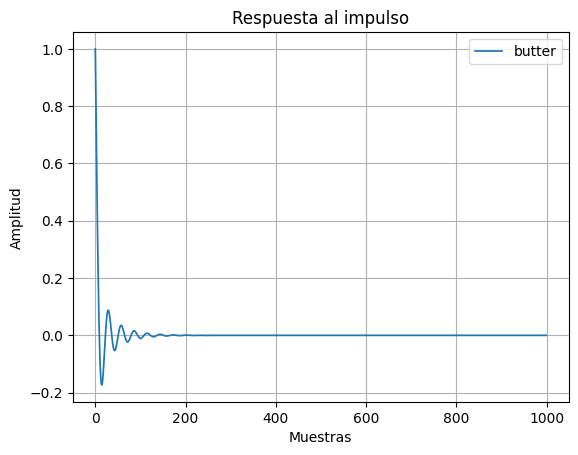

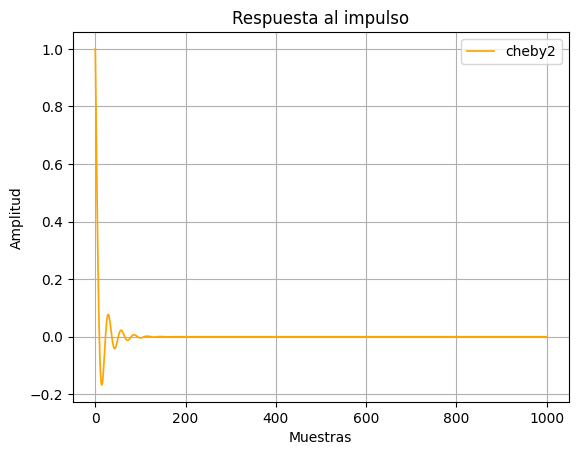

In [38]:
#%% Calcular la respuesta al impulso

delta_k = sig.unit_impulse(1000)

resp_imp_butt = sig.sosfiltfilt(sos_butt, delta_k)
resp_imp_cheby2 = sig.sosfiltfilt(sos_cheby2, delta_k)
resp_imp_cauer = sig.sosfiltfilt(sos_cauer, delta_k)


#%% Graficar respuesta al impulso

plt.figure(3)

plt.plot(resp_imp_butt, linewidth=1.25, label='butter')
plt.plot(resp_imp_cheby2, linewidth=1.25, label='cheby2')
plt.plot(resp_imp_cauer, linewidth=1.25, label='cauer')
plt.legend()
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.title("Respuesta al impulso")
plt.grid(True)
plt.figure(4)
plt.plot(resp_imp_butt, linewidth=1.25, label='butter')
plt.legend()
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.title("Respuesta al impulso")
plt.grid(True)
plt.figure(5)
plt.plot(resp_imp_cheby2, linewidth=1.25, label='cheby2',color= 'orange')

plt.legend()
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.title("Respuesta al impulso")
plt.grid(True)

plt.show()

(Analizar respuestas respuestas al impulsos, ver que son los rebotes esos cuanto dura , etc)

In [ ]:
#%% Filtrado de la señal ECG

ECG_f_butt = sig.sosfilt(sos_butt, ecg_one_lead)
ECG_f_cheby2 = sig.sosfilt(sos_cheby2, ecg_one_lead)
ECG_f_cauer = sig.sosfilt(sos_cauer, ecg_one_lead)


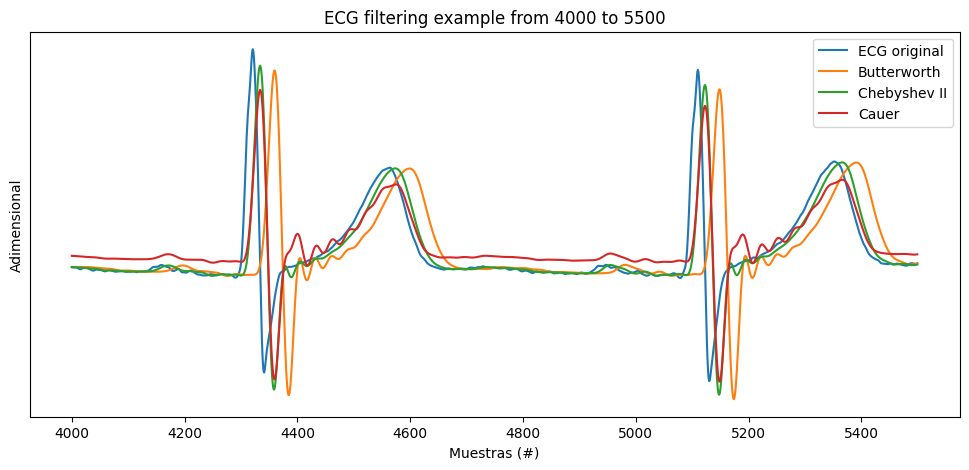

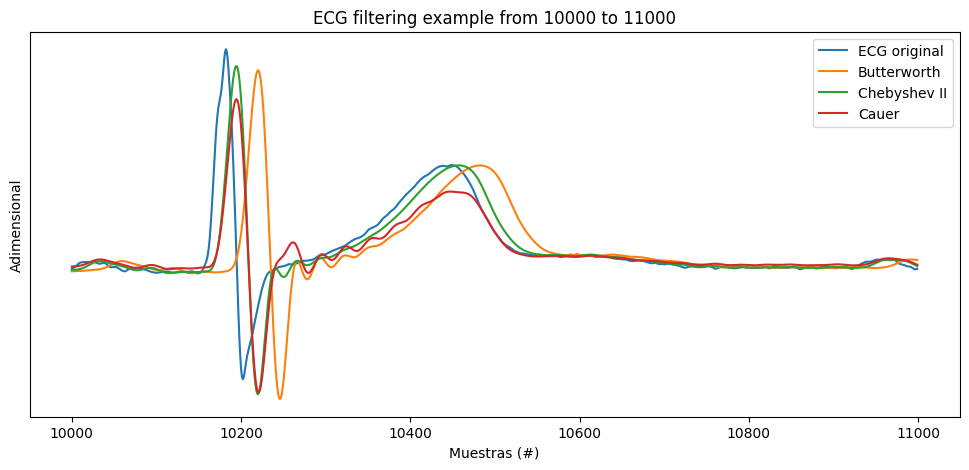

In [40]:
#%% Regiones de interés con ruido

cant_muestras = ecg_one_lead.shape[0]

regs_interes = (
    [4000, 5500],       # muestras
    [10e3, 11e3],       # muestras
)

for ii in regs_interes:

    # Intervalo limitado de 0 a cant_muestras
    inicio = int(max(0, ii[0]))
    fin = int(min(cant_muestras, ii[1]))

    zoom_region = np.arange(inicio, fin)

    plt.figure(figsize=(12, 5))

    plt.plot(zoom_region, ecg_one_lead[inicio:fin],
             label='ECG original', linewidth=1.5)

    plt.plot(zoom_region, ECG_f_butt[inicio:fin],
             label='Butterworth')

    plt.plot(zoom_region, ECG_f_cheby2[inicio:fin],
             label='Chebyshev II')

    plt.plot(zoom_region, ECG_f_cauer[inicio:fin],
             label='Cauer')

    plt.title('ECG filtering example from ' +
              str(inicio) + ' to ' + str(fin))

    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')

    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())

    plt.show()

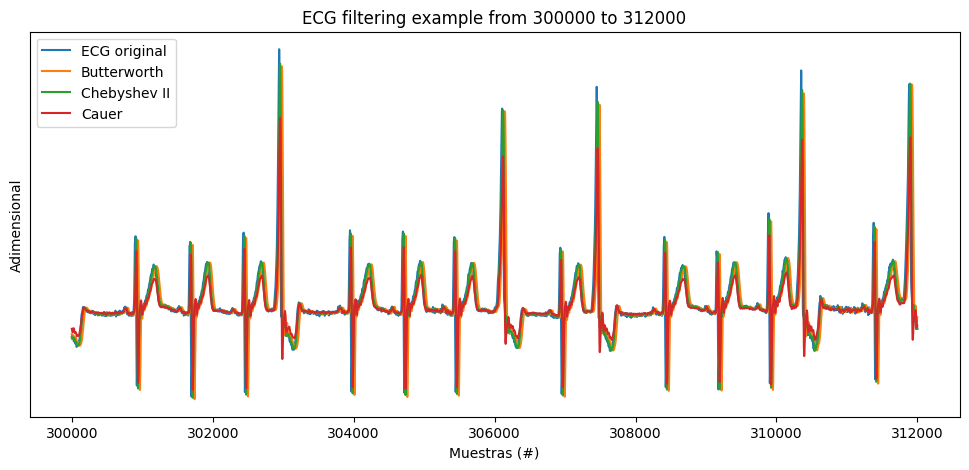

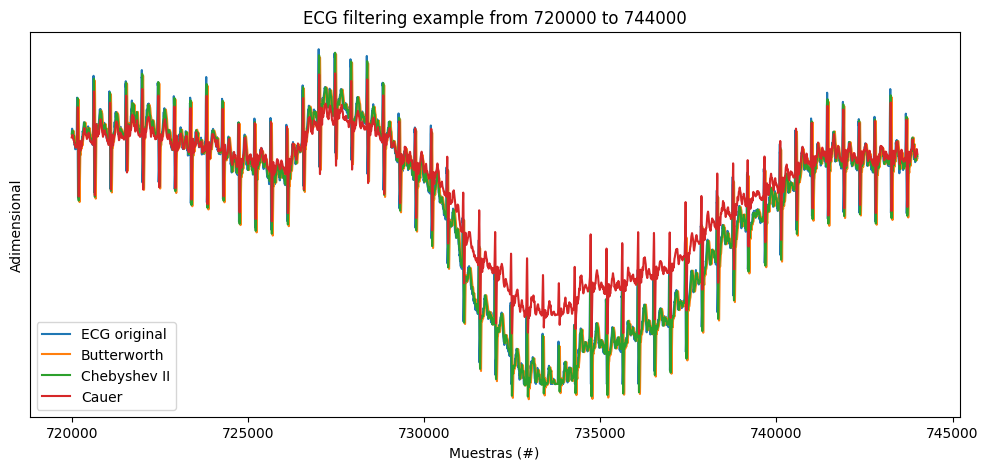

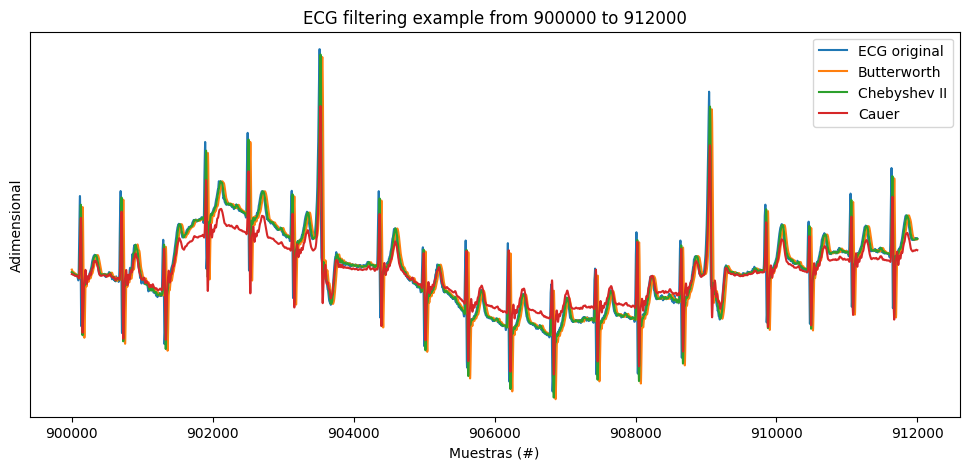

In [41]:
#%% Regiones de interés sin ruido

regs_interes = (
    np.array([5, 5.2]) * 60 * fs_ecg,   # minutos a muestras
    np.array([12, 12.4]) * 60 * fs_ecg,
    np.array([15, 15.2]) * 60 * fs_ecg,
)

for ii in regs_interes:

    # Intervalo limitado de 0 a cant_muestras
    inicio = int(max(0, ii[0]))
    fin = int(min(cant_muestras, ii[1]))

    zoom_region = np.arange(inicio, fin)

    plt.figure(figsize=(12, 5))

    plt.plot(zoom_region, ecg_one_lead[inicio:fin],
             label='ECG original', linewidth=1.5)

    plt.plot(zoom_region, ECG_f_butt[inicio:fin],
             label='Butterworth')

    plt.plot(zoom_region, ECG_f_cheby2[inicio:fin],
             label='Chebyshev II')

    plt.plot(zoom_region, ECG_f_cauer[inicio:fin],
             label='Cauer')

    plt.title('ECG filtering example from ' +
              str(inicio) + ' to ' + str(fin))

    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')

    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())

    plt.show()

In [ ]:
aplicar sos y descartar si es distorsion por otra cosa o fase 

## 2.2 Filtros FIR